# EDA salary v2: chỉ tập train có kỳ tháng rõ

Notebook bổ sung cho model đang phục vụ `v2_042e3aa1a886`. **Run All chỉ đọc dữ liệu train và model đã fit, không huấn luyện hay dùng ví dụ validation/test.**

Biểu đồ mô tả 79 tin train / 69 nhóm công ty có bằng chứng kỳ tháng, nhãn vẫn silver. Không trộn 1.078 weak train vào thống kê lương quan sát. Tập này chỉ có 5 trong 8 vai trò model hỗ trợ; không đại diện toàn thị trường. Các kết quả notebook 01 thuộc tập v1 và được giữ nguyên.

In [1]:
from pathlib import Path
import hashlib
import json
import os
import sys

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

OUT = ROOT / "outputs/eda/salary_v2_strict_train_042e3aa1a886"
OUT.mkdir(parents=True, exist_ok=True)
manifest_path = ROOT / "data/splits/v2.1.0/vn_developer/manifest.json"
manifest = json.loads(manifest_path.read_text())
item = manifest["files"]["train"]
source = ROOT / item["path"]
assert hashlib.sha256(source.read_bytes()).hexdigest() == item["sha256"]
train = pd.read_csv(source)
assert len(train) == item["rows"] == 79
assert train.leakage_group_id.nunique() == item["groups"] == 69
assert train.salary_monthly_vnd.gt(0).all()
train["salary_million"] = train.salary_monthly_vnd / 1e6
print("Train strict:", len(train), "| công ty:", train.leakage_group_id.nunique())
print("Weak train không dùng cho biểu đồ:", manifest["files"]["weak_train"]["rows"])
display(train.groupby("role").agg(tin=("record_id", "size"), trung_vi_trieu=("salary_million", "median")))

Train strict: 79 | công ty: 69
Weak train không dùng cho biểu đồ: 1078


,tin,trung_vi_trieu
role,,
Backend Developer,9,25.0
Frontend Developer,6,15.5
Full-stack Developer,11,20.0
Mobile Developer,5,17.5
Software Developer,48,17.5


## 1. Nhu cầu kỹ năng và lương theo công nghệ

Mỗi công nghệ đếm tối đa một lần/tin, chuẩn chữ thường để gộp khác biệt hoa/thường. Dùng danh mục hiển thị công nghệ của app, nên kỹ năng chưa nằm trong danh mục có thể chưa được thống kê. Trung vị lương chỉ trình bày công nghệ có ít nhất 5 tin và 5 nhóm công ty. Một tin có thể yêu cầu nhiều kỹ năng; không cộng các cột để tính số việc làm. Đây là liên hệ quan sát, không suy nhân quả.

,skill,jobs,companies,median_salary_million
23,javascript,27,24,17.50
13,css,23,20,17.50
20,html,19,16,17.00
30,mysql,17,16,20.00
41,react,17,17,18.00
5,api,16,16,20.25
18,git,15,14,18.00
22,java,13,13,20.00
36,php,12,10,12.00
49,sql,12,12,17.25


,skill,jobs,companies,median_salary_million
43,redis,6,6,25.00
46,spring,5,5,25.00
37,postgresql,8,8,23.75
29,mongodb,7,6,21.50
15,docker,6,6,21.25
52,typescript,8,8,21.00
5,api,16,16,20.25
3,angular,5,5,20.00
22,java,13,13,20.00
30,mysql,17,16,20.00


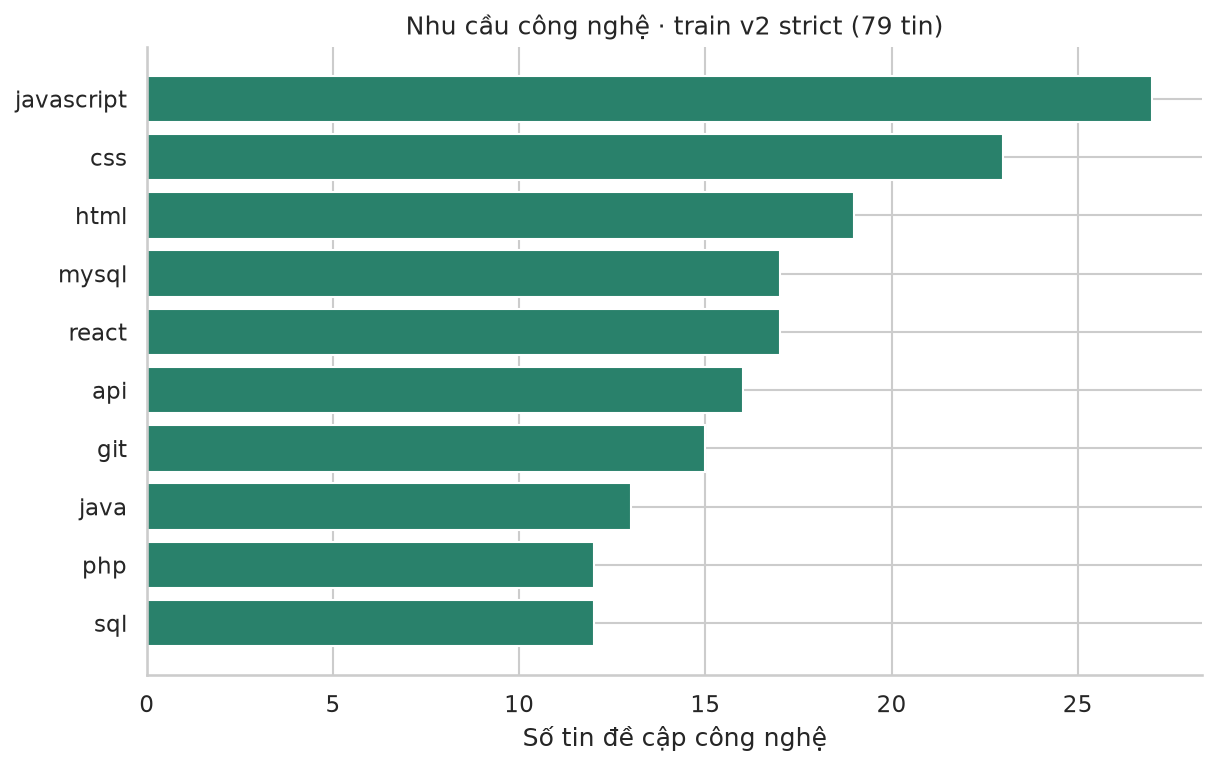

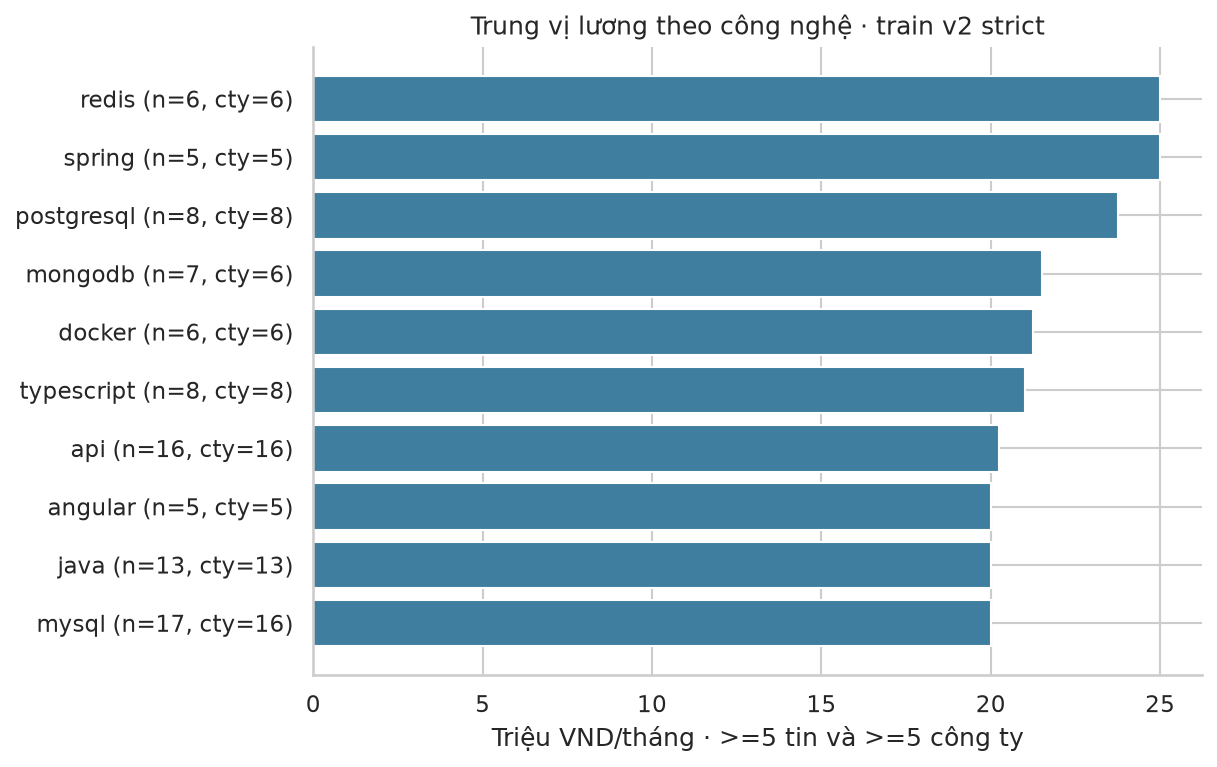

In [2]:
from backend.app.services.charts import TECHNOLOGIES

skill_rows = train.assign(skill=train.skills.fillna("").str.split(";")).explode("skill")
skill_rows["skill"] = skill_rows.skill.str.strip().str.casefold()
skill_rows = skill_rows[skill_rows.skill.isin(TECHNOLOGIES)].drop_duplicates(["record_id", "skill"])
skill_stats = skill_rows.groupby("skill").agg(
    jobs=("record_id", "nunique"), companies=("leakage_group_id", "nunique"),
    median_salary_million=("salary_million", "median")
).reset_index()
skill_stats = skill_stats.sort_values(["jobs", "skill"], ascending=[False, True])
skill_stats.to_csv(OUT / "skill_statistics.csv", index=False)
paid_skills = skill_stats[skill_stats.jobs.ge(5) & skill_stats.companies.ge(5)].sort_values(
    ["median_salary_million", "skill"], ascending=[False, True]
)
display(skill_stats.head(10))
display(paid_skills.head(10))

sns.set_theme(style="whitegrid", palette=["#29816b", "#407e9f"])
plt.rcParams.update({"font.family": "DejaVu Sans", "axes.spines.top": False, "axes.spines.right": False})
def save_plot(name, fig):
    fig.savefig(OUT / name, dpi=150, facecolor="white", bbox_inches="tight")
    display(Image(filename=str(OUT / name)))
    plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
shown = skill_stats.head(10).iloc[::-1]
ax.barh(shown.skill, shown.jobs, color="#29816b")
ax.set(title="Nhu cầu công nghệ · train v2 strict (79 tin)", xlabel="Số tin đề cập công nghệ")
save_plot("skill_demand.png", fig)

fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
shown = paid_skills.head(10).iloc[::-1]
ax.barh([f"{r.skill} (n={r.jobs}, cty={r.companies})" for r in shown.itertuples()], shown.median_salary_million, color="#407e9f")
ax.set(title="Trung vị lương theo công nghệ · train v2 strict", xlabel="Triệu VND/tháng · >=5 tin và >=5 công ty")
save_plot("skill_salary.png", fig)

## 2. Kinh nghiệm, vai trò và khu vực

Kinh nghiệm là dữ liệu đã chuẩn hóa, có thể là cận dưới yêu cầu. Pearson chỉ là tương quan tuyến tính trên mẫu train; không phải tác động nhân quả hoặc điểm dự đoán. Bảng vùng giữ nguyên nhãn nguồn; biểu đồ vùng chỉ hiển thị nhóm có ít nhất 5 tin để tránh các địa chỉ riêng quá dài và nhóm một mẫu.

Pearson r (train strict): 0.3846 | n: 79


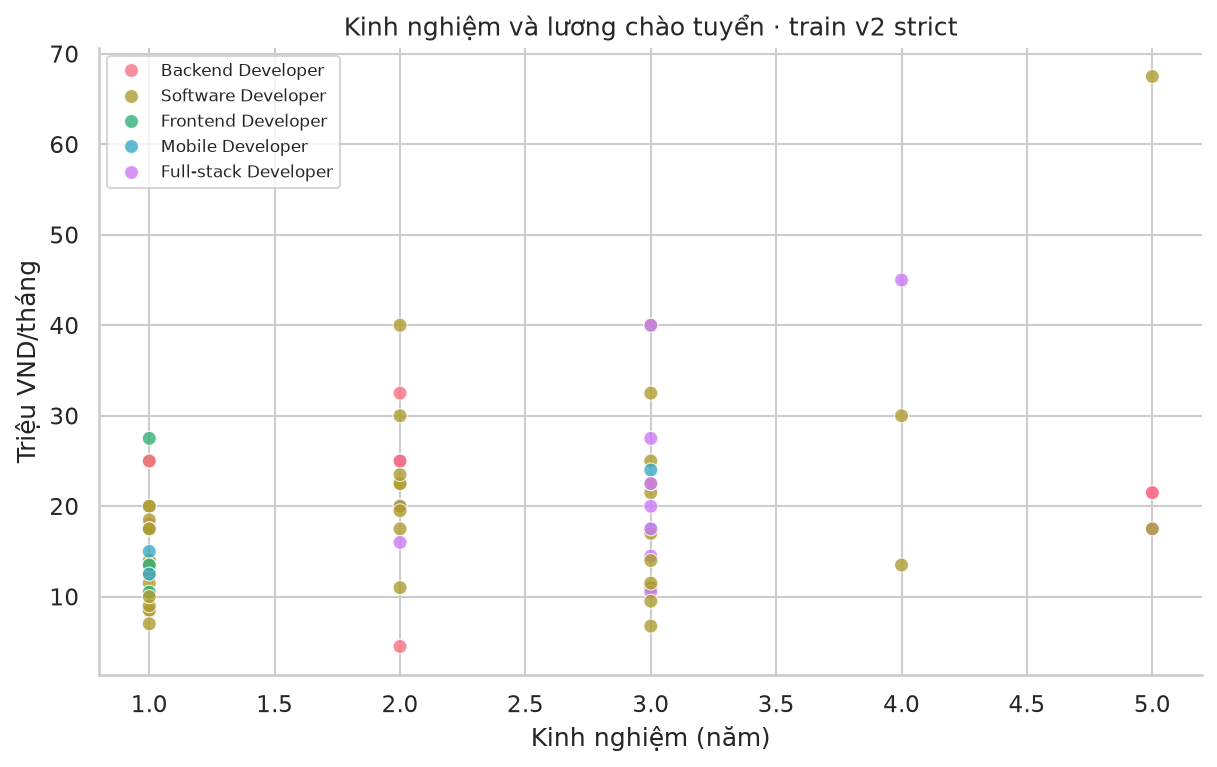

,jobs,companies,median_salary_million
role,,,
Software Developer,48,40,17.5
Full-stack Developer,11,11,20.0
Backend Developer,9,8,25.0
Frontend Developer,6,6,15.5
Mobile Developer,5,5,17.5


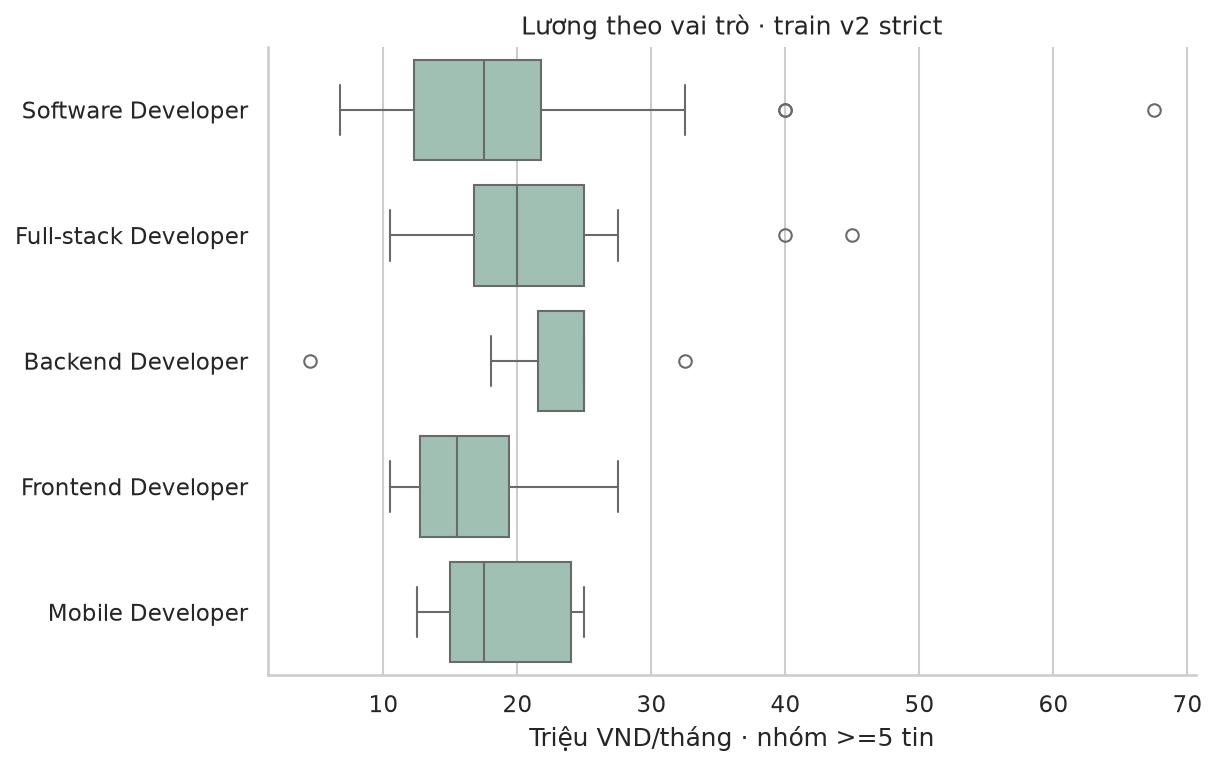

,jobs,companies,median_salary_million
location,,,
TP.HCM,35,31,17.50
Hà Nội,32,26,20.00
Đà Nẵng,2,2,16.75
337 Phạm Văn Đồng.,1,1,9.00
"Cần Giuộc Lô H.09, đường số 1, KCN Long Hậu, xã Cần Giuộc Long An",1,1,11.50
"Dĩ An Số 2A, Đường số 8, Khu công nghiệp Sóng Thần 1 Binh Duong",1,1,27.50
"Hai Phong Lô M, KCN Tràng Duệ, Hải Phòng Hai Phong",1,1,12.50
Hai Phong Ouransoft Hai Phong,1,1,8.50
"Hung Yen Lô 11, Khu Công nghiệp Hoàng Mai Hung Yen",1,1,7.00


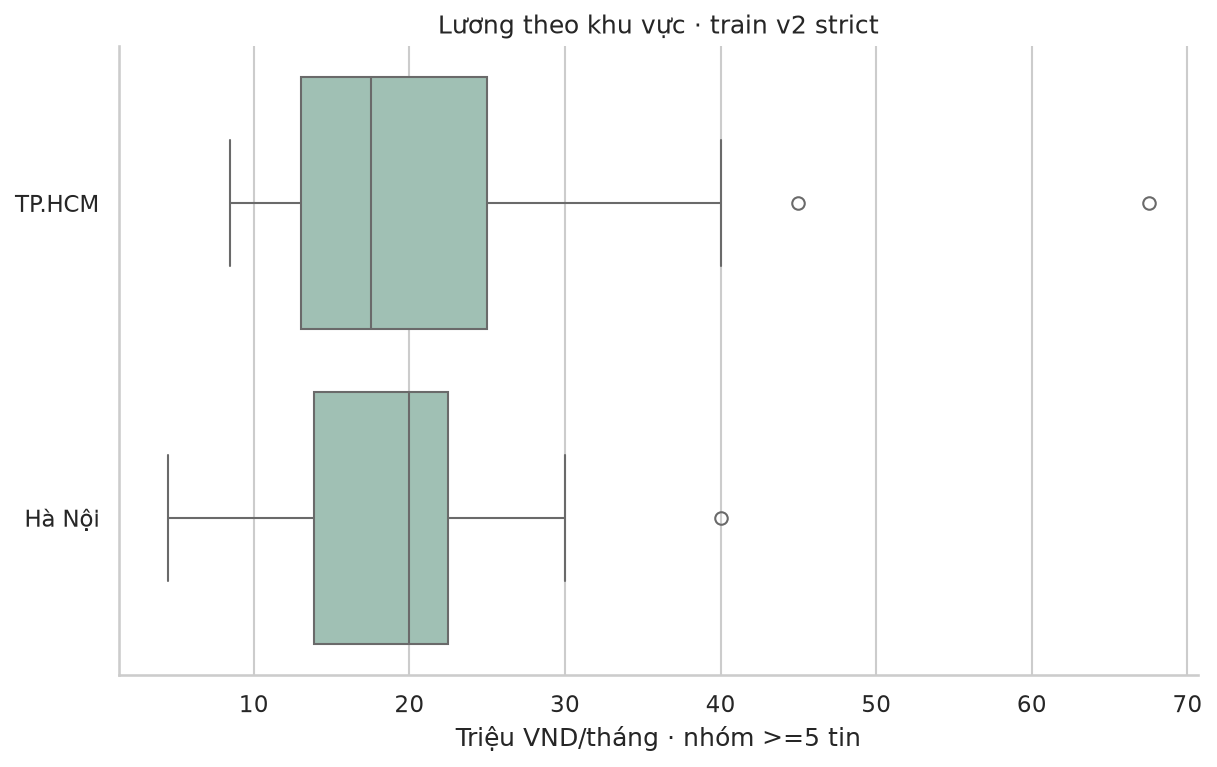

In [3]:
complete = train.dropna(subset=["experience_years", "salary_million"])
pearson = float(complete.experience_years.corr(complete.salary_million))
print("Pearson r (train strict):", round(pearson, 4), "| n:", len(complete))
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
sns.scatterplot(data=complete, x="experience_years", y="salary_million", hue="role", ax=ax, alpha=.8, s=45)
ax.set(title="Kinh nghiệm và lương chào tuyển · train v2 strict", xlabel="Kinh nghiệm (năm)", ylabel="Triệu VND/tháng")
ax.legend(title=None, fontsize=8)
save_plot("experience_salary.png", fig)

for column, label in [("role", "vai trò"), ("location", "khu vực")]:
    stats = train.groupby(column).agg(jobs=("record_id", "size"), companies=("leakage_group_id", "nunique"), median_salary_million=("salary_million", "median")).sort_values("jobs", ascending=False)
    stats.to_csv(OUT / f"{column}_statistics.csv")
    display(stats)
    names = stats[stats.jobs.ge(5)].index.tolist()
    fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
    sns.boxplot(data=train[train[column].isin(names)], x="salary_million", y=column, order=names, ax=ax, color="#9bc5b5")
    ax.set(title=f"Lương theo {label} · train v2 strict", xlabel="Triệu VND/tháng · nhóm >=5 tin", ylabel="")
    save_plot(f"salary_by_{column}.png", fig)

## 3. Kỹ năng liên hệ với dự đoán lương trong Ridge đang phục vụ

Bảng dưới lấy hệ số của Ridge đã fit và số mẫu từ snapshot train đã kiểm tra checksum. Model này học 79 strict + 1.078 weak với trọng số yếu 0,3; **khác phạm vi 79 mẫu của các biểu đồ trên**. Skill feature là binary, hệ số dương mô tả chênh lệch dự đoán khi đổi cờ kỹ năng và giữ feature khác cố định. Không phải lợi ích thu nhập đã kiểm chứng và không cho biết nên học gì trong mọi hoàn cảnh. App còn đòi ít nhất 5 mẫu cùng vai trò trước khi đề xuất.

In [4]:
from backend.app.services.salary import salary_service

service = salary_service()
assert service.experiment == "v2_042e3aa1a886"
associations = service.associations.copy()
associations.to_csv(OUT / "ridge_skill_associations_train.csv", index=False)
display(associations.head(10))
print("Model train snapshot:", len(service.train), "tin; không fit model trong notebook này")

,skill,train_rows,coefficient_vnd
55,pytorch,15,9.115319e+06
63,rust,10,7.052129e+06
56,rails,13,5.439878e+06
8,asp.net core,23,4.752640e+06
17,docker,208,4.748047e+06
9,aws,143,3.364885e+06
28,golang,45,3.354467e+06
20,express,39,3.274599e+06
10,azure,78,2.604885e+06
36,kafka,91,2.528717e+06


Model train snapshot: 1157 tin; không fit model trong notebook này


## 4. Lưu bằng chứng

Thống kê/PNG giữ ở thư mục output riêng, không thay notebook hoặc biểu đồ v1. Chỉ đọc train cho phân tích. Khởi tạo dịch vụ đọc lại scalar metric lịch sử và kiểm tra lineage artifact; không đọc ví dụ validation/test để tạo thống kê hay điều chỉnh model.

In [5]:
summary = {
    "dataset": "salary v2.1.0 strict train only",
    "input_path": item["path"], "input_sha256": item["sha256"],
    "dataset_manifest_sha256": hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    "rows": len(train), "company_groups": int(train.leakage_group_id.nunique()),
    "roles": train.role.value_counts().to_dict(),
    "experience_salary_pearson": pearson,
    "skill_salary_minimum_jobs": 5, "skill_salary_minimum_companies": 5,
    "top_demand": skill_stats.head(5).to_dict("records"),
    "top_salary_skills": paid_skills.head(5).to_dict("records"),
    "ridge_association_scope": {"experiment": service.experiment, "train_rows": len(service.train), "quality": service.label_quality},
    "validation_or_test_examples_used": False, "training_started": False,
    "limits": ["Train-only descriptive statistics, not independent evaluation", "Silver labels; advertised range midpoint, gross/net unknown", "Weak labels excluded from descriptive plots but present in fitted Ridge", "Only 5 roles in strict train; no population or causal claim", "Technology display lexicon can omit unlisted skills"]
}
summary["files"] = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(OUT.iterdir()) if p.suffix in {".csv", ".png"}}
(OUT / "summary.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2) + "\n")
print("Saved:", OUT)
print("Đối chiếu phần 3 và 6 trong reports/BAO_CAO_NOI_DUNG.md; không chọn model bằng các thống kê này.")

Saved: /Users/scara2906/Downloads/ML/outputs/eda/salary_v2_strict_train_042e3aa1a886
Đối chiếu phần 3 và 6 trong reports/BAO_CAO_NOI_DUNG.md; không chọn model bằng các thống kê này.
